## Module 3: Computational Drug Discovery Project Template

Complete the sections below as a team. Remove the word “Template” only if it appears in the final notebook title.

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 
Provide a brief (<200 word) background of obesity, available treatments, and especially why improved treatments are needed. Your answers may include for example: 
Prevalence & incidence, Symptoms, Diagnosis, Standard of care treatments (& reimbursement), Disease progression & prognosis, Biological mechanisms (anatomy, organ physiology, cell & molecular physiology), Clinical Trials/next-gen therapies.

Please provide citations and/or hyperlinks to where you obtained information (including AI) for each of the bullet points.

Obesity is a chronic disease influenced by genetic, hormonal, environmental, and behavioral factors that affect appetite, metabolism, and fat storage. In 2022, about one in eight people worldwide lived with obesity, showing how substantial obesity is ([WHO](https://www.who.int/news/item/01-03-2024-one-in-eight-people-are-now-living-with-obesity)). In adults, obesity is classified as a body mass index (BMI) of at least 30 kg/m² and increases the risk of type 2 diabetes, cardiovascular disease, and several cancers ([WHO](https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight)). As discussed in Module 3 Lecture 1, altered signaling between the gut, brain, pancreas, and adipose tissue can disrupt fullness and glucose regulation. GLP-1 receptor agonists, such as semaglutide, target these pathways to support appetite control and weight loss. Treatment includes nutrition and physical activity changes, medications, and metabolic surgery. 

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

### Task 1a: Model and fitting method
We adapted the instructor's `fit_semaglutide_GLP1R.py` example, keeping its brute-force search and `curve_fit` approach. The only additional analysis is an approximate 95% confidence interval for Cavalitide Kd.

The model assumes GLP1 and Cavalitide compete for one receptor binding site at equilibrium, and that either ligand fully activates the receptor. GLP1 is fixed at the example's fasting concentration, 0.015 nM, with Kd = 0.17 nM. Free ligand concentrations are approximated by the supplied concentrations. Only Cavalitide Kd is fitted. All 12 observations receive equal weight. The 0.38 nM semaglutide value is the instructor's reference.

### Task 1b: Fit and plot


Brute-force Kd2 = 0.074 nM (SSE = 0.0054)
Fitted Kd2 = 0.077 nM (SSE = 0.0052)
Kd standard error = 0.00454 nM
Approximate 95% confidence interval = [0.06806, 0.08587] nM


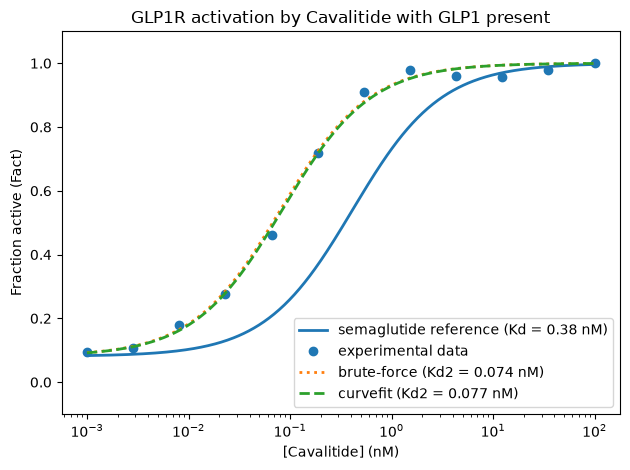

In [ ]:
%matplotlib inline
# fit_cavalitide_GLP1R.py
# Adapted from the instructor's fit_semaglutide_GLP1R.py example.

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
Kd2 = 0.38 # semaglutide reference
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] semaglutide or cavalitide

# Load the data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

# Approach 1: Brute force optimization of Kd2. try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf
for Kd2_try in Kd2_candidates:
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_brute:
        SSE_brute = SSE
        Kd2_brute = Kd2_try
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})")

# Approach 2: Python curvefit of Kd2. related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})")


# Extra analysis: approximate 95% confidence interval for Cavalitide Kd.
# The square root of the fitted variance gives the standard error.
Kd2_se = np.sqrt(pcov[0, 0])
ci_low = Kd2_fit - 1.96 * Kd2_se
ci_high = Kd2_fit + 1.96 * Kd2_se
print(f"Kd standard error = {Kd2_se:.5f} nM")
print(f"Approximate 95% confidence interval = [{ci_low:.5f}, {ci_high:.5f}] nM")

plt.figure()
line, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2), lw=2,
                     label="semaglutide reference (Kd = 0.38 nM)")
plt.semilogx(L2_loaded, Fact_loaded, "o", c=line.get_color(),
             label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2,
             label=f"brute-force (Kd2 = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
             label=f"curvefit (Kd2 = {Kd2_fit:.3f} nM)")

plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present")
plt.legend(loc="best")
plt.tight_layout()
plt.savefig("cavalitide_fit.png", dpi=200)
plt.show()


### Task 1c: Results and interpretation
The fitted Cavalitide Kd is approximately 0.077 nM, compared with the instructor's semaglutide reference of 0.38 nM. Cavalitide's Kd is about 4.9 times lower, indicating higher affinity. It can therefore reach the same modeled receptor activation at a lower free drug concentration when GLP1 is fixed. The fitted curve follows the observed increase toward full activation. The brute-force estimate is approximately 0.074 nM (SSE = 0.0054), close to the continuous fit (SSE = 0.0052). 

Higher affinity could be an advantage if lower free concentrations can provide the desired activation. A possible tradeoff is that a concentration chosen for semaglutide could produce more activation than intended for Cavalitide, so dosing would need to be adjusted. This fit also does not establish side effects, weight loss, length of action, or oral absorption. Those would require other models or experiments. Both drugs approach the same maximum activation in the assumed model.

### Extra analysis: Approximate 95% confidence interval
We calculated the standard error as `sqrt(pcov[0, 0])` and the approximate interval as Kd ± 1.96 × standard error. The standard error is approximately 0.00454 nM, giving an interval of 0.06806–0.08587 nM. This estimates uncertainty in the fitted Cavalitide Kd.

With only 12 points, the interval is approximate and does not include uncertainty from model assumptions. It is not a formal two-drug statistical comparison because uncertainty in semaglutide Kd was not included.

*Sources: instructor's `fit_semaglutide_GLP1R.py`, supplied `cavalitide_data.csv`, and Module 3 Lecture 2 (slides 14–15). Covariance interpretation: [SciPy curve_fit documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html).*

*AI assistance for Task 1: ChatGPT assisted in writing the approximate confidence-interval calculation and helped write the interpretation.*


## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

TBD

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

TBD

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

SciPy community. *scipy.optimize.curve_fit.* SciPy documentation. https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html

World Health Organization. (2024, March 1). https://www.who.int/news/item/01-03-2024-one-in-eight-people-are-now-living-with-obesity

World Health Organization. https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight



## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*